# Statistik
## 01 - Beschreibende (Deskriptive) Statistik

Die **Statistik** beschäftigt sich mit wissenschaftlichen Methoden des Sammelns, der Gliederung und der Analyse von Daten - und mit dem Ziehen von Schlüssen und Treffen von Entscheidungen aufgrund dieser Analysen.

Man unterscheidet zwei große Bereiche:

| Bereich | Ziel | Methoden |
|---------|------|----------|
| **Beschreibende (deskriptive) Statistik** | Daten erfassen, beschreiben und übersichtlich darstellen | Tabellen, Grafiken, Kenngrößen (Mittelwert, Streuung, …) |
| **Beurteilende (induktive) Statistik** | Von einer Stichprobe auf die Grundgesamtheit schließen | Schätzen, Testen, Konfidenzintervalle |

> **Beachte:** Statistische Aussagen gelten immer nur für eine **große Anzahl** von Objekten. Sie haben im Allgemeinen kaum eine Aussagekraft für einzelne Objekte.

In diesem Notebook befassen wir uns mit der **beschreibenden Statistik** - dem Fundament.

### Lernziele

- Du verstehst die Begriffe **Grundgesamtheit**, **Stichprobe** und **Stichprobenumfang**.
- Du kennst den Unterschied zwischen **Merkmalen** und **Merkmalsausprägungen**.
- Du kannst **qualitative** und **quantitative** Merkmale unterscheiden (inkl. Skalenniveaus).
- Du kannst einfache Daten mit Python erfassen und erste Übersichten erstellen.

---

### 1. Grundbegriffe

Bevor wir Daten analysieren können, müssen wir die Sprache der Statistik verstehen:

#### Grundgesamtheit und Stichprobe

> **Definition:**
> - Die **Grundgesamtheit** ist die **Menge** aller zu beurteilenden Objekte. Ihr **Umfang** $N$ ist die Anzahl der Elemente.
> - Eine **Stichprobe** ist eine **Teilmenge** der Grundgesamtheit, die zur Prüfung **zufällig** entnommen wird. Ihr **Umfang** ist $n$.
> - *Zufällig* bedeutet, dass jedes Objekt der Grundgesamtheit **dieselbe Chance** hat, in die Stichprobe aufgenommen zu werden.
> - Die Stichprobe muss **repräsentativ** sein - d.h. sie muss die typischen Eigenschaften der Grundgesamtheit widerspiegeln.

Im Allgemeinen ist $N$ sehr viel größer als $n$, also $N \gg n$.

**Warum Stichproben?** Eine Vollerhebung (alle $N$ Objekte untersuchen) ist oft zu teuer, zu zeitaufwendig oder schlicht unmöglich. Wenn die Stichprobe repräsentativ ist, können wir von ihr auf die Grundgesamtheit schließen.

---

#### Beispiel: Grundgesamtheit vs. Stichprobe

| Situation | Grundgesamtheit ($N$) | Stichprobe ($n$) |
|-----------|----------------------|-----------------|
| Getränkekonsum Jugendlicher einer Region | Alle Jugendliche (16–20 J.) der Region, $N \approx 12\,000$ | 50 befragte Jugendliche in einer Disco |
| Qualitätskontrolle Schrauben | Tagesproduktion: $N = 5\,000\,000$ | $n = 1\,000$ zufällig geprüfte Stück → $0{,}02\,\%$ |

In [1]:
# === KONFIGURATION: Beispiel Grundgesamtheit & Stichprobe ===
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Simuliere eine "Grundgesamtheit" von 12.000 Jugendlichen
# Getränkekonsum pro Samstagabend (in Getränken)
N = 12_000
grundgesamtheit = np.random.poisson(lam=3, size=N)  # Durchschnitt: 3 Getränke

# Zufällige Stichprobe von 50 Personen
n = 50
stichprobe = np.random.choice(grundgesamtheit, size=n, replace=False)

print(f"Grundgesamtheit:  N = {N}")
print(f"  Mittelwert:     {grundgesamtheit.mean():.2f} Getränke")
print(f"  Std.-Abw.:      {grundgesamtheit.std():.2f}")
print()
print(f"Stichprobe:       n = {n}")
print(f"  Mittelwert:     {stichprobe.mean():.2f} Getränke")
print(f"  Std.-Abw.:      {stichprobe.std():.2f}")
print()
print(f"Verhältnis n/N:   {n/N:.4%}")

Grundgesamtheit:  N = 12000
  Mittelwert:     2.99 Getränke
  Std.-Abw.:      1.72

Stichprobe:       n = 50
  Mittelwert:     2.88 Getränke
  Std.-Abw.:      1.69

Verhältnis n/N:   0.4167%


### 2. Merkmale und Merkmalsausprägungen

Wenn wir Daten erheben, untersuchen wir bestimmte **Eigenschaften** der Objekte. Diese Eigenschaften nennt man **Merkmale**, und die möglichen Werte, die ein Merkmal annehmen kann, heißen **Merkmalsausprägungen**.

> **Definition:**
> - Ein **Merkmal** (auch: Variable) ist eine Eigenschaft, die an den Objekten der Grundgesamtheit untersucht wird.
> - Die **Merkmalsausprägungen** sind die konkreten Werte, die ein Merkmal annehmen kann.

**Beispiel:** Beim Kundenumfrage-Bogen könnte ein Merkmal *„Geschlecht"* sein, mit den Ausprägungen *männlich, weiblich, divers*. Ein anderes Merkmal wäre *„Alter"* mit Ausprägungen wie *18, 25, 42, …*

#### Qualitative vs. Quantitative Merkmale

| Art | Beschreibung | Beispiele |
|-----|-------------|-----------|
| **Qualitativ** | Beschreiben eine Eigenschaft, die **nicht numerisch** messbar ist | Geschlecht, Farbe, Beruf, Religion |
| **Quantitativ** | Beschreiben eine Eigenschaft, die **numerisch** messbar ist | Alter, Einkommen, Temperatur, Gewicht |

Quantitative Merkmale können weiter unterteilt werden:

| Unterart | Beschreibung | Beispiele |
|----------|-------------|-----------|
| **Diskret** | Nur **abzählbar** viele Werte möglich (meist ganzzahlig) | Anzahl Kinder, Würfelaugen, Schulnoten |
| **Stetig** | Kann **jeden** Wert in einem Intervall annehmen | Körpergröße, Temperatur, Zeit |

---

### 3. Skalen in der Statistik (Skalenniveaus)

Das **Skalenniveau** eines Merkmals bestimmt, welche mathematische Operationen sinnvoll sind. Es gibt vier Stufen - von „wenig Information" bis „viel Information":

#### Qualitative Skalen

| Skala | Erklärung | Beispiele | Erlaubte Operationen |
|-------|-----------|-----------|----------------------|
| **Nominalskala** | Die Ausprägungen bilden **keine natürliche Reihenfolge**. Sie stehen gleichberechtigt nebeneinander. Man kann sie nur **unterscheiden**. | Farbe, Autokennzeichen, Geschlecht, Religion | $=$, $\neq$ |
| **Ordinalskala** | Zwischen den Ausprägungen besteht eine **natürliche Reihung** (*„größer als"*-Beziehung). Die **Abstände** sind aber nicht quantifizierbar. | Schulnoten, Güteklassen (Eier, Obst), Rang beim Autorennen | $=$, $\neq$, $<$, $>$ |

> *nomen* (lat.) = Name, Benennung - *ordo* (lat.) = Reihenfolge, Ordnung

#### Metrische (quantitative) Skalen

| Skala | Erklärung | Beispiele | Erlaubte Operationen |
|-------|-----------|-----------|----------------------|
| **Intervallskala** | Abstände zwischen Ausprägungen sind messbar und vergleichbar. Der **Nullpunkt** ist allerdings **willkürlich** festgelegt → **kein sinnvoller Quotient**. | Temperatur in °C/°F, Kalenderzeitrechnung | $=$, $\neq$, $<$, $>$, $+$, $-$ |
| **Verhältnisskala** | Wie Intervallskala, aber mit **absolutem Nullpunkt**. Dadurch sind **Quotienten sinnvoll** (*„doppelt so viel"*). | Körpermasse, Alter, Einkommen, Temperatur in Kelvin | $=$, $\neq$, $<$, $>$, $+$, $-$, $\times$, $\div$ |

> **Beispiel Intervall vs. Verhältnis:** *20 °C ist nicht „doppelt so warm" wie 10 °C* (Intervallskala - willkürlicher Nullpunkt). Aber: *Franz ist doppelt so alt wie Karl* (Verhältnisskala - absoluter Nullpunkt bei 0 Jahren).

> **Merke:** Die Kelvinskala hat einen absoluten Nullpunkt bei 0 K (= $-273{,}15$ °C), deshalb ist Temperatur in Kelvin verhältnisskaliert, während Celsius und Fahrenheit nur intervallskaliert sind.

#### Zusammenfassung: Hierarchie der Skalen

$$\text{Nominalskala} \subset \text{Ordinalskala} \subset \text{Intervallskala} \subset \text{Verhältnisskala}$$

Jede höhere Skala erbt die Eigenschaften der niedrigeren. Je höher das Skalenniveau, desto **mehr statistische Verfahren** können angewandt werden.

---

In [ ]:
# === Beispiel: Merkmale und ihre Skalenniveaus ===
import pandas as pd

# Ein kleiner Beispieldatensatz: Kundenbefragung
daten = pd.DataFrame({
    "Name":        ["Anna", "Ben", "Clara", "David", "Eva", "Felix", "Gina", "Hugo"],
    "Geschlecht":  ["w", "m", "w", "m", "w", "m", "w", "m"],           # Nominal
    "Schulnote":   [2, 1, 3, 2, 1, 4, 2, 3],                           # Ordinal
    "Temperatur_C":[36.5, 37.1, 36.8, 38.2, 36.6, 37.0, 36.9, 37.5],   # Intervall
    "Alter":       [23, 19, 31, 27, 22, 35, 28, 20],                    # Verhältnis
    "Einkommen":   [2800, 1200, 4500, 3200, 2100, 5100, 3700, 1500],    # Verhältnis
})

# Skalenniveau-Zuordnung anzeigen
skalen_info = {
    "Merkmal":       ["Geschlecht", "Schulnote", "Temperatur (°C)", "Alter", "Einkommen (€)"],
    "Skalenniveau":  ["Nominal",    "Ordinal",   "Intervall",       "Verhältnis", "Verhältnis"],
    "Qualitativ/Quantitativ": ["Qualitativ", "Qualitativ", "Quantitativ", "Quantitativ", "Quantitativ"],
    "Diskret/Stetig":["-",         "Diskret",   "Stetig",          "Diskret",    "Stetig"],
}

print("=== Datensatz (Auszug) ===")
print(daten.to_string(index=False))
print()
print("=== Merkmals-Übersicht ===")
print(pd.DataFrame(skalen_info).to_string(index=False))

=== Datensatz (Auszug) ===
 Name Geschlecht  Schulnote  Temperatur_C  Alter  Einkommen
 Anna          w          2          36.5     23       2800
  Ben          m          1          37.1     19       1200
Clara          w          3          36.8     31       4500
David          m          2          38.2     27       3200
  Eva          w          1          36.6     22       2100
Felix          m          4          37.0     35       5100
 Gina          w          2          36.9     28       3700
 Hugo          m          3          37.5     20       1500

=== Merkmals-Übersicht ===
        Merkmal Skalenniveau Qualitativ/Quantitativ Diskret/Stetig
     Geschlecht      Nominal             Qualitativ              —
      Schulnote      Ordinal             Qualitativ        Diskret
Temperatur (°C)    Intervall            Quantitativ         Stetig
          Alter   Verhältnis            Quantitativ        Diskret
  Einkommen (€)   Verhältnis            Quantitativ         Stetig


### 4. Häufigkeitsverteilungen

Eine der ersten Aufgaben der deskriptiven Statistik ist es, die Daten **zusammenzufassen**. Dafür zählen wir, wie oft jede Merkmalsausprägung vorkommt.

#### Absolute und relative Häufigkeit

| Begriff | Symbol | Bedeutung | Formel |
|---------|--------|-----------|--------|
| **Absolute Häufigkeit** | $H_i$ | Wie oft kommt die Ausprägung $x_i$ vor? | Zählung |
| **Relative Häufigkeit** | $h_i$ | Welcher **Anteil** entfällt auf $x_i$? | $h_i = \dfrac{H_i}{n}$ |
| **Kumulierte Häufigkeit** | $F_i$ | Wie groß ist der Anteil **bis einschließlich** $x_i$? | $F_i = \displaystyle\sum_{j=1}^{i} h_j$ |

Es gilt immer:
$$\sum_{i=1}^{k} H_i = n \qquad \text{und} \qquad \sum_{i=1}^{k} h_i = 1$$

> **Kumulierte Häufigkeit** ist nur bei Merkmalen mit einer **natürlichen Reihenfolge** (ab Ordinalskala) sinnvoll.

---

In [2]:
# === Häufigkeitstabelle aus dem Beispieldatensatz ===
import pandas as pd

# Schulnoten aus dem Datensatz (ordinal → kumulierte Häufigkeit sinnvoll)
noten = pd.Series([2, 1, 3, 2, 1, 4, 2, 3], name="Schulnote")
n_ges = len(noten)

# Häufigkeitstabelle aufbauen
haeufigkeit = noten.value_counts().sort_index()
tabelle = pd.DataFrame({
    "Ausprägung (xᵢ)": haeufigkeit.index,
    "Abs. Häufigkeit (Hᵢ)": haeufigkeit.values,
    "Rel. Häufigkeit (hᵢ)": (haeufigkeit.values / n_ges).round(4),
    "Kum. Häufigkeit (Fᵢ)": (haeufigkeit.values / n_ges).cumsum().round(4),
})

print(f"Merkmal: Schulnote  |  n = {n_ges}")
print()
print(tabelle.to_string(index=False))
print()
print(f"Kontrolle: Σ Hᵢ = {haeufigkeit.values.sum()}  |  Σ hᵢ = {(haeufigkeit.values / n_ges).sum():.4f}")

Merkmal: Schulnote  |  n = 8

 Ausprägung (xᵢ)  Abs. Häufigkeit (Hᵢ)  Rel. Häufigkeit (hᵢ)  Kum. Häufigkeit (Fᵢ)
               1                     2                 0.250                 0.250
               2                     3                 0.375                 0.625
               3                     2                 0.250                 0.875
               4                     1                 0.125                 1.000

Kontrolle: Σ Hᵢ = 8  |  Σ hᵢ = 1.0000


### 5. Diagrammtypen - Darstellung von Häufigkeiten

Die Wahl des **richtigen Diagramms** hängt vom **Skalenniveau** des Merkmals ab:

#### Qualitative Merkmale (Nominal- & Ordinalskala)

| Diagramm | Beschreibung | Wann verwenden? |
|----------|-------------|-----------------|
| **Kreisdiagramm** (Tortendiagramm) | Anteile als Kreissektoren → zeigt die relative Häufigkeit | Gut bei **wenigen** Ausprägungen (z.B. Geschlecht, Lieblingsfach) |
| **Stabdiagramm** (Balkendiagramm) | Einzelne Stäbe pro Ausprägung, **mit Lücken** dazwischen | Standard für qualitative/ordinale Daten |

> **Wichtig:** Stäbe haben Lücken → die Ausprägungen sind **diskrete Kategorien**, nicht zusammenhängend.

#### Metrische Merkmale (Intervall- & Verhältnisskala)

| Diagramm | Beschreibung | Wann verwenden? |
|----------|-------------|-----------------|
| **Histogramm** | Balken **ohne Lücken** - die Breite entspricht dem Klassenintervall, die Höhe (oder Fläche) der Häufigkeit | Für **stetige** oder in Klassen eingeteilte Daten (z.B. Körpergröße, Einkommen) |
| **Boxplot** (Kastengrafik) | Zeigt **Median**, **Quartile**, **Spannweite** und **Ausreißer** auf einen Blick - ideal zum Vergleich mehrerer Verteilungen | Für metrische Daten, wenn **Lage und Streuung** kompakt dargestellt werden sollen |
| **Liniendiagramm / Polygonzug** | Punkte verbunden durch Linien | Für **zeitliche Verläufe** oder geordnete metrische Werte |

> **Histogramm vs. Stabdiagramm:** Beim Histogramm berühren sich die Balken - das zeigt, dass die Werte auf einer **kontinuierlichen Skala** liegen. Beim Stabdiagramm stehen die Stäbe getrennt.

> **Boxplot:** Kommt in **Abschnitt 7** (Streuungsmaße / IQR) vor, da er direkt auf den Quartilen aufbaut.

---

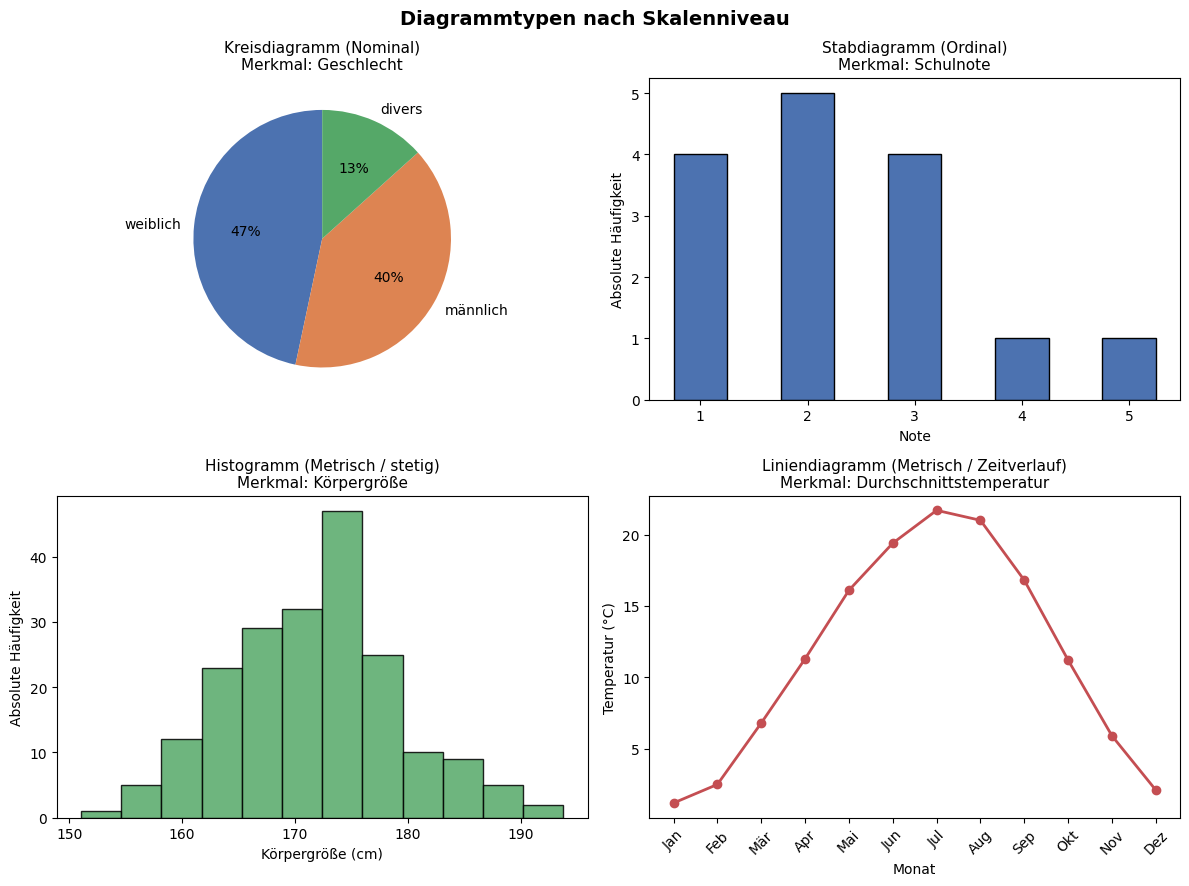

In [ ]:
# === Diagrammtypen: Qualitativ vs. Metrisch ===
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Diagrammtypen nach Skalenniveau", fontsize=14, fontweight="bold")

# --- 1. Kreisdiagramm (Nominal) ---
geschlecht = pd.Series(["männlich", "weiblich", "divers", "weiblich", "männlich",
                         "weiblich", "männlich", "weiblich", "männlich", "weiblich",
                         "männlich", "weiblich", "divers", "männlich", "weiblich"])
counts_g = geschlecht.value_counts()
colors_pie = ["#4C72B0", "#DD8452", "#55A868"]
axes[0, 0].pie(counts_g, labels=counts_g.index, autopct="%1.0f%%", startangle=90, colors=colors_pie)
axes[0, 0].set_title("Kreisdiagramm (Nominal)\nMerkmal: Geschlecht", fontsize=11)

# --- 2. Stabdiagramm (Ordinal) ---
noten = pd.Series([2, 1, 3, 2, 1, 4, 2, 3, 1, 2, 3, 5, 2, 3, 1])
h_noten = noten.value_counts().sort_index()
bar_colors = ["#4C72B0"] * len(h_noten)
axes[0, 1].bar(h_noten.index, h_noten.values, width=0.5, color=bar_colors, edgecolor="black")
axes[0, 1].set_xlabel("Note")
axes[0, 1].set_ylabel("Absolute Häufigkeit")
axes[0, 1].set_title("Stabdiagramm (Ordinal)\nMerkmal: Schulnote", fontsize=11)
axes[0, 1].set_xticks(h_noten.index)

# --- 3. Histogramm (Metrisch / stetig) ---
koerpergroesse = np.random.normal(loc=172, scale=8, size=200)
axes[1, 0].hist(koerpergroesse, bins=12, color="#55A868", edgecolor="black", alpha=0.85)
axes[1, 0].set_xlabel("Körpergröße (cm)")
axes[1, 0].set_ylabel("Absolute Häufigkeit")
axes[1, 0].set_title("Histogramm (Metrisch / stetig)\nMerkmal: Körpergröße", fontsize=11)

# --- 4. Liniendiagramm (Metrisch / Zeitverlauf) ---
monate = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
temperatur = [1.2, 2.5, 6.8, 11.3, 16.1, 19.4, 21.7, 21.0, 16.8, 11.2, 5.9, 2.1]
axes[1, 1].plot(monate, temperatur, marker="o", color="#C44E52", linewidth=2)
axes[1, 1].set_xlabel("Monat")
axes[1, 1].set_ylabel("Temperatur (°C)")
axes[1, 1].set_title("Liniendiagramm (Metrisch / Zeitverlauf)\nMerkmal: Durchschnittstemperatur", fontsize=11)
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 6. Lagemaße - Wo liegt das „Zentrum" der Daten?

Ein zentrales Ziel der deskriptiven Statistik ist es, einen **typischen** oder **repräsentativen Wert** für einen Datensatz zu finden.

---

#### 6.1 Arithmetisches Mittel (Durchschnitt)

Das **arithmetische Mittel** $\bar{x}$ ist die Summe aller Werte geteilt durch ihre Anzahl:

$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i = \frac{x_1 + x_2 + \cdots + x_n}{n}$$

**Eigenschaften:**
- Berücksichtigt **jeden** Datenwert → reagiert empfindlich auf **Ausreißer**
- Sinnvoll ab **Intervallskala** (Abstände müssen vergleichbar sein)

**Beispiel:** Noten $\{2, 1, 3, 2, 1, 4, 2, 3\}$ → $\bar{x} = \frac{2+1+3+2+1+4+2+3}{8} = \frac{18}{8} = 2{,}25$

---

#### 6.2 Gewichtetes Arithmetisches Mittel

In vielen Situationen sollen nicht alle Werte **gleich stark** in den Durchschnitt einfließen - z.B. wenn Schularbeiten stärker zählen als Mitarbeit, oder größere Unternehmen einen Aktienindex stärker beeinflussen.

> **Definition:** Gegeben sind $n$ Werte $x_1, \ldots, x_n$ mit Gewichten $w_1, \ldots, w_n$ ($w_i > 0$). Dann ist das **gewichtete arithmetische Mittel**:
>
> $$\bar{x}_w = \frac{\sum_{i=1}^{n} w_i \cdot x_i}{\sum_{i=1}^{n} w_i}$$

Sind alle Gewichte gleich, ergibt sich das gewöhnliche arithmetische Mittel.

**Beispiel - Zeugnisnote:**

| Prüfung | Note | Gewicht |
|---------|------|---------|
| Schularbeit 1 | 2 | 2 |
| Schularbeit 2 | 3 | 2 |
| Mündlich | 1 | 1 |
| Mitarbeit | 2 | 1 |

$$\bar{x}_w = \frac{2 \cdot 2 + 2 \cdot 3 + 1 \cdot 1 + 1 \cdot 2}{2 + 2 + 1 + 1} = \frac{13}{6} \approx 2{,}17 \qquad \text{(ungewichtet: } \bar{x} = 2{,}0\text{)}$$

> **Zusammenhang mit Häufigkeiten:** Relative Häufigkeiten $h_i$ können als Gewichte aufgefasst werden: $\bar{x} = \sum_{j=1}^{k} h_j \cdot x_j$

---

=== Zeugnisnoten-Beispiel ===
  Prüfung             Note  Gewicht
  ---------------------------------
  Schularbeit 1          2        2
  Schularbeit 2          3        2
  Mündlich               1        1
  Mitarbeit              2        1

  Ungewichtetes Mittel:  x̄   = 2.00
  Gewichtetes Mittel:    x̄_w = 2.17



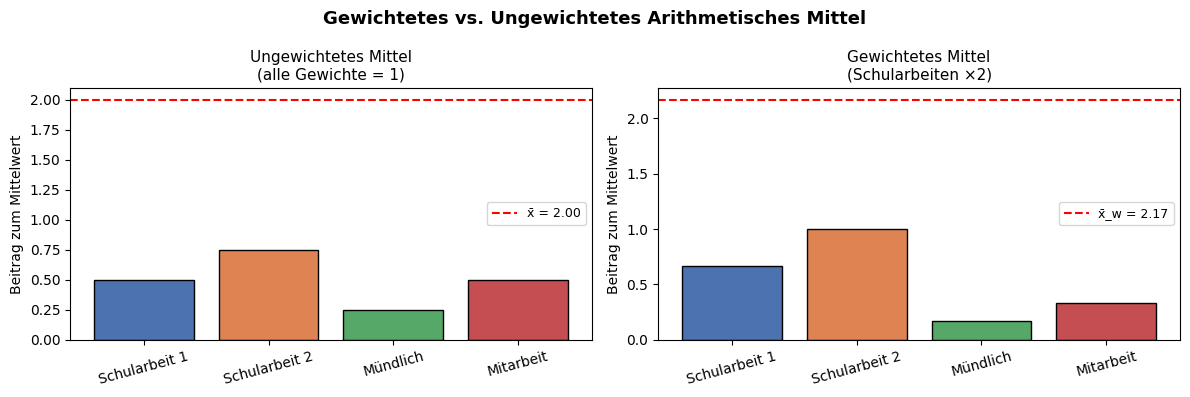

In [2]:
# === Gewichtetes vs. Ungewichtetes Arithmetisches Mittel ===
import numpy as np
import matplotlib.pyplot as plt

# --- Beispiel: Zeugnisnote mit Gewichtung ---
noten    = np.array([2, 3, 1, 2])
gewichte = np.array([2, 2, 1, 1])  # Schularbeiten zählen doppelt
labels   = ["Schularbeit 1", "Schularbeit 2", "Mündlich", "Mitarbeit"]

# Berechnung
mittel_ungewichtet = np.mean(noten)
mittel_gewichtet   = np.average(noten, weights=gewichte)

print("=== Zeugnisnoten-Beispiel ===")
print(f"  {'Prüfung':<18} {'Note':>5} {'Gewicht':>8}")
print("  " + "-" * 33)
for lab, note, gew in zip(labels, noten, gewichte):
    print(f"  {lab:<18} {note:>5} {gew:>8}")
print()
print(f"  Ungewichtetes Mittel:  x̄   = {mittel_ungewichtet:.2f}")
print(f"  Gewichtetes Mittel:    x̄_w = {mittel_gewichtet:.2f}")
print()

# --- Visualisierung: Beitrag jeder Note zum gewichteten Mittel ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Ungewichtet
beitraege_ung = noten / len(noten)
farben = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
axes[0].bar(labels, beitraege_ung, color=farben, edgecolor="black")
axes[0].axhline(mittel_ungewichtet, color="red", linestyle="--", linewidth=1.5,
                label=f"x̄ = {mittel_ungewichtet:.2f}")
axes[0].set_ylabel("Beitrag zum Mittelwert")
axes[0].set_title("Ungewichtetes Mittel\n(alle Gewichte = 1)", fontsize=11)
axes[0].legend(fontsize=9)
axes[0].tick_params(axis="x", rotation=15)

# Gewichtet
anteil_gewichte = gewichte / gewichte.sum()
beitraege_gew = noten * anteil_gewichte
axes[1].bar(labels, beitraege_gew, color=farben, edgecolor="black")
axes[1].axhline(mittel_gewichtet, color="red", linestyle="--", linewidth=1.5,
                label=f"x̄_w = {mittel_gewichtet:.2f}")
axes[1].set_ylabel("Beitrag zum Mittelwert")
axes[1].set_title("Gewichtetes Mittel\n(Schularbeiten ×2)", fontsize=11)
axes[1].legend(fontsize=9)
axes[1].tick_params(axis="x", rotation=15)

fig.suptitle("Gewichtetes vs. Ungewichtetes Arithmetisches Mittel", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

#### 6.3 Median (Zentralwert)

Der **Median** $\tilde{x}$ teilt die **geordnete** Datenreihe in zwei gleich große Hälften - 50 % der Werte liegen darunter, 50 % darüber.

**Berechnung:**
1. Daten der Größe nach ordnen: $x_{(1)} \leq x_{(2)} \leq \cdots \leq x_{(n)}$
2. Dann:

$$\tilde{x} = \begin{cases} x_{\left(\frac{n+1}{2}\right)} & \text{wenn } n \text{ ungerade} \\[6pt] \dfrac{1}{2}\left(x_{\left(\frac{n}{2}\right)} + x_{\left(\frac{n}{2}+1\right)}\right) & \text{wenn } n \text{ gerade} \end{cases}$$

**Eigenschaften:**
- **Robust** gegenüber Ausreißern (ein einzelner Extremwert ändert den Median kaum)
- Sinnvoll ab **Ordinalskala**

**Beispiel:** Geordnete Noten $\{1, 1, 2, 2, 2, 3, 3, 4\}$ → $n = 8$ (gerade) → $\tilde{x} = \frac{x_{(4)} + x_{(5)}}{2} = \frac{2 + 2}{2} = 2{,}0$

---

#### 6.4 Modus (Modalwert)

Der **Modus** $x_{\text{mod}}$ ist der Wert, der am **häufigsten** vorkommt.

**Eigenschaften:**
- Das einzige Lagemaß, das schon ab der **Nominalskala** sinnvoll ist (z.B. „häufigste Farbe")
- Kann **mehrdeutig** sein: zwei Werte mit gleicher Höchsthäufigkeit → **bimodal**; mehrere → **multimodal**
- Bei stetigen Daten oft wenig aussagekräftig → dann Klassen bilden

**Beispiel:** Noten $\{1, 1, 2, 2, 2, 3, 3, 4\}$ → $x_{\text{mod}} = 2$ (kommt 3× vor)

---

#### Wann welches Lagemaß?

| Situation | Empfehlung |
|-----------|------------|
| Symmetrische Verteilung, keine Ausreißer | **Arithmetisches Mittel** - nutzt alle Informationen |
| Unterschiedliche Bedeutung der Werte | **Gewichtetes Mittel** - berücksichtigt Wichtigkeit |
| Schiefe Verteilung oder Ausreißer vorhanden | **Median** - robuster, weniger verzerrt |
| Ordinalskala (z.B. Schulnoten) | **Median** - Abstände nicht gleich, Mittel fragwürdig |
| Nominalskala (z.B. Farbe, Geschlecht) | **Modus** - einziges sinnvolles Lagemaß |

> **Faustregel:** Wenn Mittelwert und Median stark voneinander abweichen, ist die Verteilung **schief** oder es gibt **Ausreißer**.

---

--- Ohne Ausreißer ---
  Daten:   [np.int64(1200), np.int64(1500), np.int64(2100), np.int64(2800), np.int64(2900), np.int64(3200), np.int64(3700), np.int64(4500)]
  x̄ (Mittelwert) = 2,738 €
  x̃ (Median)     = 2,850 €
  Differenz       = 112 €

--- Mit Ausreißer (95.000 €) ---
  Daten:   [np.int64(1200), np.int64(1500), np.int64(2100), np.int64(2800), np.int64(2900), np.int64(3200), np.int64(3700), np.int64(4500), np.int64(95000)]
  x̄ (Mittelwert) = 12,989 €
  x̃ (Median)     = 2,900 €
  Differenz       = 10,089 €



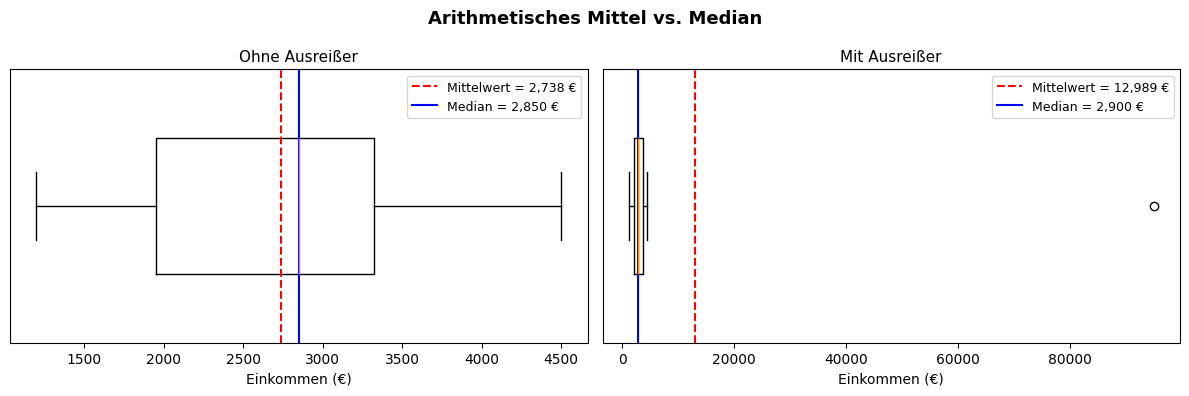

In [ ]:
# === Mittelwert vs. Median - Vergleich mit und ohne Ausreißer ===
import numpy as np
import matplotlib.pyplot as plt

# --- Datensatz: Monatseinkommen (in Euro) ---
einkommen_normal = np.array([2800, 1200, 4500, 3200, 2100, 3700, 1500, 2900])
einkommen_ausreisser = np.append(einkommen_normal, 95000)  # CEO-Gehalt als Ausreißer

for label, daten in [("Ohne Ausreißer", einkommen_normal), ("Mit Ausreißer (95.000 €)", einkommen_ausreisser)]:
    mittel = np.mean(daten)
    median = np.median(daten)
    print(f"--- {label} ---")
    print(f"  Daten:   {sorted(daten)}")
    print(f"  x̄ (Mittelwert) = {mittel:,.0f} €")
    print(f"  x̃ (Median)     = {median:,.0f} €")
    print(f"  Differenz       = {abs(mittel - median):,.0f} €")
    print()

# --- Visualisierung ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label, daten in [(axes[0], "Ohne Ausreißer", einkommen_normal),
                          (axes[1], "Mit Ausreißer", einkommen_ausreisser)]:
    ax.boxplot(daten, vert=False, widths=0.5)
    mittel = np.mean(daten)
    median = np.median(daten)
    ax.axvline(mittel, color="red", linestyle="--", linewidth=1.5, label=f"Mittelwert = {mittel:,.0f} €")
    ax.axvline(median, color="blue", linestyle="-", linewidth=1.5, label=f"Median = {median:,.0f} €")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Einkommen (€)")
    ax.legend(fontsize=9)
    ax.set_yticks([])

fig.suptitle("Arithmetisches Mittel vs. Median", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 7. Streuungsmaße - Wie stark streuen die Daten?

Lagemaße allein reichen nicht aus - zwei Datensätze können denselben Mittelwert haben, aber völlig unterschiedlich verteilt sein. **Streuungsmaße** beschreiben, wie weit die Werte um das Zentrum herum verteilt sind.

#### Spannweite (Range)

Das einfachste Streuungsmaß - die Differenz zwischen dem größten und dem kleinsten Wert:

$$R = x_{\max} - x_{\min}$$

**Vorteil:** Leicht zu berechnen.
**Nachteil:** Berücksichtigt nur 2 Werte → extrem **empfindlich** gegenüber Ausreißern.

---

#### Quartile und Interquartilsabstand (IQR)

Quartile teilen die geordnete Datenreihe in **vier gleich große Teile**:

| Quartil | Symbol | Bedeutung |
|---------|--------|-----------|
| Unteres Quartil | $Q_1$ | 25 % der Werte liegen darunter |
| Median | $Q_2 = \tilde{x}$ | 50 % der Werte liegen darunter |
| Oberes Quartil | $Q_3$ | 75 % der Werte liegen darunter |

Der **Interquartilsabstand** (IQR) misst die Streuung der "mittleren 50 %" der Daten:

$$\text{IQR} = Q_3 - Q_1$$

> **Vorteil:** Robust gegenüber Ausreißern - genau wie der Median ignoriert der IQR die extremen Werte.

---

#### Der Boxplot (Kastengrafik)

Der **Boxplot** fasst die wichtigsten Lagemaße und Streuungsmaße in einer einzigen Grafik zusammen:

| Bestandteil | Bedeutung |
|-------------|-----------|
| **Box** (Kasten) | Reicht von $Q_1$ bis $Q_3$ → enthält die mittleren 50 % der Daten |
| **Strich in der Box** | Median ($Q_2 = \tilde{x}$) |
| **Whisker** (Antennen) | Reichen bis zum letzten Datenpunkt innerhalb von $1{,}5 \cdot \text{IQR}$ ab $Q_1$ bzw. $Q_3$ |
| **Punkte** außerhalb | **Ausreißer** - Werte jenseits der Whisker |

> **Warum $1{,}5 \cdot \text{IQR}$?** Bei einer Normalverteilung liegen ca. 99,3 % aller Werte innerhalb dieser Grenzen. Alles außerhalb ist „ungewöhnlich".

Der Boxplot eignet sich besonders gut zum **Vergleich** mehrerer Gruppen, da Lage und Streuung auf einen Blick erkennbar sind.

---

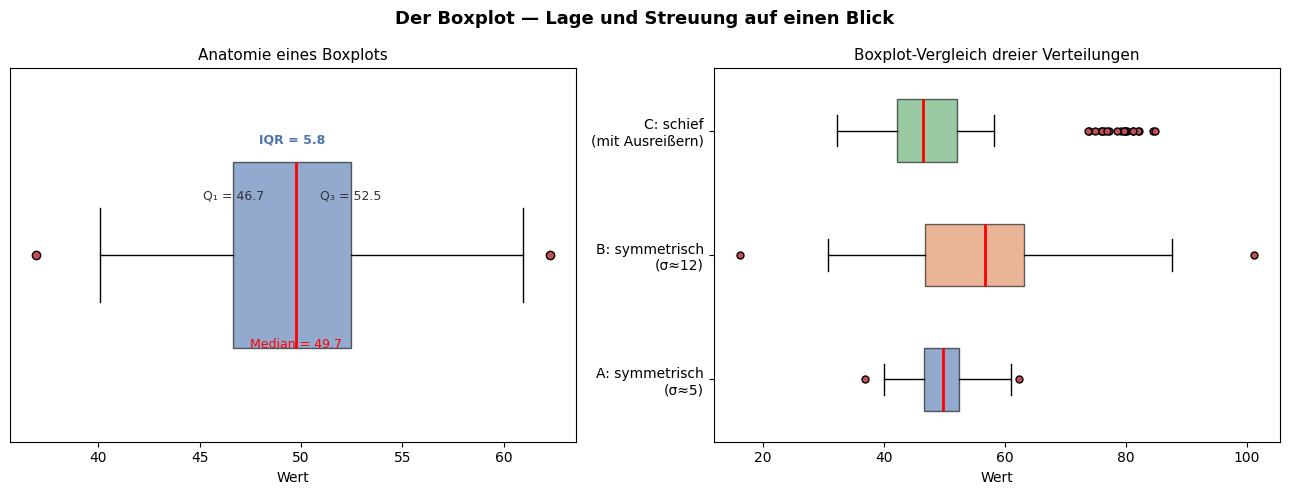

In [ ]:
# === Boxplot: Aufbau und Vergleich ===
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Drei Datensätze zum Vergleich
daten_A = np.random.normal(loc=50, scale=5, size=150)           # symmetrisch, geringe Streuung
daten_B = np.random.normal(loc=55, scale=12, size=150)          # symmetrisch, hohe Streuung
daten_C = np.concatenate([np.random.normal(45, 6, 130),         # schief mit Ausreißern
                          np.random.normal(80, 3, 20)])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Links: Anatomie eines einzelnen Boxplots ---
bp = axes[0].boxplot(daten_A, vert=False, widths=0.5, patch_artist=True,
                     boxprops=dict(facecolor="#4C72B0", alpha=0.6),
                     medianprops=dict(color="red", linewidth=2),
                     flierprops=dict(marker="o", markerfacecolor="#C44E52", markersize=6))

Q1, median, Q3 = np.percentile(daten_A, [25, 50, 75])
IQR = Q3 - Q1

# Beschriftungen
axes[0].annotate(f"Q₁ = {Q1:.1f}", xy=(Q1, 1.15), fontsize=9, ha="center", color="#333")
axes[0].annotate(f"Median = {median:.1f}", xy=(median, 0.75), fontsize=9, ha="center", color="red")
axes[0].annotate(f"Q₃ = {Q3:.1f}", xy=(Q3, 1.15), fontsize=9, ha="center", color="#333")
axes[0].annotate(f"IQR = {IQR:.1f}", xy=((Q1 + Q3) / 2, 1.30), fontsize=9, ha="center",
                 color="#4C72B0", fontweight="bold")
axes[0].set_title("Anatomie eines Boxplots", fontsize=11)
axes[0].set_xlabel("Wert")
axes[0].set_yticks([])

# --- Rechts: Vergleich dreier Verteilungen ---
bp2 = axes[1].boxplot([daten_A, daten_B, daten_C], vert=False, widths=0.5, patch_artist=True,
                       tick_labels=["A: symmetrisch\n(σ≈5)", "B: symmetrisch\n(σ≈12)", "C: schief\n(mit Ausreißern)"],
                       flierprops=dict(marker="o", markerfacecolor="#C44E52", markersize=5))
farben = ["#4C72B0", "#DD8452", "#55A868"]
for patch, farbe in zip(bp2["boxes"], farben):
    patch.set_facecolor(farbe)
    patch.set_alpha(0.6)
for med in bp2["medians"]:
    med.set_color("red")
    med.set_linewidth(2)

axes[1].set_title("Boxplot-Vergleich dreier Verteilungen", fontsize=11)
axes[1].set_xlabel("Wert")

fig.suptitle("Der Boxplot - Lage und Streuung auf einen Blick", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

#### Varianz und Standardabweichung

Wir brauchen ein Streuungsmaß, das **alle** Datenwerte berücksichtigt. Die Idee: Messen, wie weit jeder Wert vom Mittelwert $\bar{x}$ abweicht.

**Warum nicht einfach den Durchschnitt der Abweichungen nehmen?**

$$\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x}) = 0 \quad \text{(immer!)}$$

Positive und negative Abweichungen heben sich gegenseitig auf. Lösung: Die Abweichungen **quadrieren**.

---

#### Empirische Varianz $s^2$

> **Definition:** Die **empirische Varianz** ist das arithmetische Mittel der quadrierten Abweichungen vom Mittelwert:
>
> $$s^2 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2$$

Alternativ mit Häufigkeiten (wenn $k$ verschiedene Ausprägungen $x_1, \ldots, x_k$ mit absoluten Häufigkeiten $H_1, \ldots, H_k$):

$$s^2 = \frac{1}{n} \sum_{j=1}^{k} H_j \cdot (x_j - \bar{x})^2 = \sum_{j=1}^{k} h_j \cdot (x_j - \bar{x})^2$$

> **Hinweis:** Manchmal wird statt $\frac{1}{n}$ der Faktor $\frac{1}{n-1}$ verwendet (sog. **korrigierte Stichprobenvarianz**). Für die beschreibende Statistik (gesamte Daten bekannt) verwenden wir $\frac{1}{n}$.

---

#### Standardabweichung $s$

Die Varianz hat den Nachteil, dass sie in **quadrierten Einheiten** angegeben ist (z.B. €²). Die **Standardabweichung** behebt das:

$$s = \sqrt{s^2} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2}$$

> Die Standardabweichung hat **dieselbe Einheit** wie die Daten und ist daher direkt interpretierbar: *„Die Werte weichen im Durchschnitt um $s$ vom Mittelwert ab."*

#### Zusammenfassung: Streuungsmaße im Überblick

| Maß | Formel | Robust? | Sinnvoll ab |
|-----|--------|---------|-------------|
| **Spannweite** $R$ | $x_{\max} - x_{\min}$ | Nein | Ordinalskala |
| **IQR** | $Q_3 - Q_1$ | Ja | Ordinalskala |
| **Varianz** $s^2$ | $\frac{1}{n}\sum(x_i - \bar{x})^2$ | Nein | Intervallskala |
| **Standardabweichung** $s$ | $\sqrt{s^2}$ | Nein | Intervallskala |

---

--- Geringe Streuung (σ≈5) ---
  Mittelwert x̄     = 49.80
  Median x̃         = 49.98
  Spannweite R     = 26.70
  Q1 = 46.47  |  Q3 = 52.50  |  IQR = 6.03
  Varianz s²       = 21.56
  Std.-Abw. s      = 4.64

--- Hohe Streuung (σ≈15) ---
  Mittelwert x̄     = 51.29
  Median x̃         = 51.18
  Spannweite R     = 106.41
  Q1 = 40.91  |  Q3 = 60.31  |  IQR = 19.40
  Varianz s²       = 218.09
  Std.-Abw. s      = 14.77



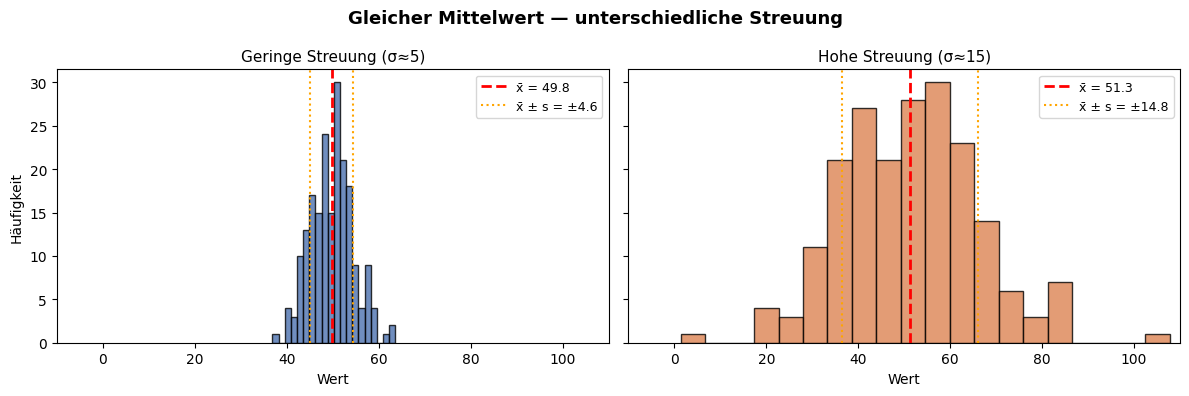

In [ ]:
# === Streuungsmaße im Vergleich ===
import numpy as np
import matplotlib.pyplot as plt

# Zwei Datensätze mit GLEICHEM Mittelwert, aber unterschiedlicher Streuung
np.random.seed(42)
daten_eng   = np.random.normal(loc=50, scale=5, size=200)   # geringe Streuung
daten_breit = np.random.normal(loc=50, scale=15, size=200)  # hohe Streuung

for label, d in [("Geringe Streuung (σ≈5)", daten_eng), ("Hohe Streuung (σ≈15)", daten_breit)]:
    print(f"--- {label} ---")
    print(f"  Mittelwert x̄     = {np.mean(d):.2f}")
    print(f"  Median x̃         = {np.median(d):.2f}")
    print(f"  Spannweite R     = {np.ptp(d):.2f}")
    Q1, Q3 = np.percentile(d, [25, 75])
    print(f"  Q1 = {Q1:.2f}  |  Q3 = {Q3:.2f}  |  IQR = {Q3 - Q1:.2f}")
    varianz = np.mean((d - np.mean(d))**2)  # empirische Varianz (1/n)
    print(f"  Varianz s²       = {varianz:.2f}")
    print(f"  Std.-Abw. s      = {np.sqrt(varianz):.2f}")
    print()

# --- Visualisierung: gleicher Mittelwert, verschiedene Streuung ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, label, d, farbe in [(axes[0], "Geringe Streuung (σ≈5)", daten_eng, "#4C72B0"),
                              (axes[1], "Hohe Streuung (σ≈15)", daten_breit, "#DD8452")]:
    ax.hist(d, bins=20, color=farbe, edgecolor="black", alpha=0.8)
    ax.axvline(np.mean(d), color="red", linestyle="--", linewidth=2, label=f"x̄ = {np.mean(d):.1f}")
    s = np.sqrt(np.mean((d - np.mean(d))**2))
    ax.axvline(np.mean(d) - s, color="orange", linestyle=":", linewidth=1.5, label=f"x̄ ± s = ±{s:.1f}")
    ax.axvline(np.mean(d) + s, color="orange", linestyle=":", linewidth=1.5)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Wert")
    ax.legend(fontsize=9)
    ax.set_xlim(-10, 110)

axes[0].set_ylabel("Häufigkeit")
fig.suptitle("Gleicher Mittelwert - unterschiedliche Streuung", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---

## Verständnis-Check

*Löse die folgenden Aufgaben auf Papier.*

**Aufgabe 1:** Gegeben sind die Temperaturen (°C) einer Woche: $18, 21, 19, 25, 22, 20, 23$.

a) Berechne den Mittelwert $\bar x$ und den Median $\tilde x$.

b) Berechne die Spannweite $R$ und den Interquartilsabstand $IQR$.

c) Berechne die Varianz $s^2$ und die Standardabweichung $s$.

**Aufgabe 2:** Ein Datensatz hat den Boxplot: $\text{Min}=10, Q_1=25, \tilde x=35, Q_3=50, \text{Max}=80$.

a) Wie groß ist der $IQR$?

b) Ab welchem Wert gilt ein Datenpunkt als Ausreißer (nach der $1{,}5 \cdot IQR$-Regel)?

**Aufgabe 3:** Nenne für jedes Skalenniveau (Nominal, Ordinal, Intervall, Verhältnis) ein Beispiel und gib an, welche Lagemaße sinnvoll sind.

**Aufgabe 4:** Zwei Klassen schreiben denselben Test. Klasse A: $\bar x = 72, s = 5$. Klasse B: $\bar x = 72, s = 15$.

Beschreibe den Unterschied und was die Standardabweichung hier aussagt.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

Sortiert: $18, 19, 20, 21, 22, 23, 25$

a) $\bar x = \frac{18+21+19+25+22+20+23}{7} = \frac{148}{7} \approx 21{,}14$

$\tilde x = 21$ (4. Wert von 7)

b) $R = 25 - 18 = 7$

$Q_1 = 19{,}5$ (Median der unteren Hälfte: $18, 19, 20$), $Q_3 = 22{,}5$ (Median der oberen: $22, 23, 25$)

$IQR = 22{,}5 - 19{,}5 = 3$

c) $s^2 = \frac{1}{7}\left[(18-21{,}14)^2 + \ldots + (25-21{,}14)^2\right] \approx 4{,}69$

$s = \sqrt{4{,}69} \approx 2{,}17$ °C
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

a) $IQR = Q_3 - Q_1 = 50 - 25 = 25$

b) Untere Grenze: $Q_1 - 1{,}5 \cdot IQR = 25 - 37{,}5 = -12{,}5$

Obere Grenze: $Q_3 + 1{,}5 \cdot IQR = 50 + 37{,}5 = 87{,}5$

Da $\text{Max} = 80 < 87{,}5$: keine Ausreißer nach oben. Werte $> 87{,}5$ oder $< -12{,}5$ wären Ausreißer.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

| Skala | Beispiel | Sinnvolle Lagemaße |
|-------|----------|-------------------|
| Nominal | Augenfarbe (blau, braun, grün) | Nur **Modus** |
| Ordinal | Schulnoten (1–5) | Modus, **Median** |
| Intervall | Temperatur in °C | Modus, Median, **Mittelwert** |
| Verhältnis | Körpergröße in cm | Modus, Median, Mittelwert |
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

Beide Klassen haben denselben Mittelwert (72 Punkte), aber:

- **Klasse A** ($s = 5$): Die Ergebnisse liegen eng um 72 → homogene Leistung.
- **Klasse B** ($s = 15$): Die Ergebnisse streuen stark → einige sehr gut, einige sehr schwach.

Die Standardabweichung misst, wie stark die einzelnen Werte vom Mittelwert abweichen. Ein größeres $s$ bedeutet mehr Ungleichheit.
</details>

---

## Zusammenfassung

Beschreibende Statistik reduziert Daten auf ihre wesentlichen Merkmale: Lage, Streuung und Form.

Das **Skalenniveau** bestimmt, welche Maße zulässig sind. Auf Nominalniveau (Augenfarbe, Postleitzahl) ist nur der Modus sinnvoll. Erst ab Intervallniveau (Temperatur, Testergebnis) ist der Mittelwert aussagekräftig. Das Skalenniveau zu kennen ist deshalb der erste Schritt jeder Auswertung.

Die **Lagemaße** beschreiben das Zentrum der Daten. Mittelwert, Median und Modus messen dasselbe Konzept auf unterschiedliche Arten. Der Mittelwert reagiert empfindlich auf Ausreißer; der Median nicht. Bei schiefen Verteilungen wie Einkommen ist der Median deshalb oft der informativere Wert. Der Modus ist der einzige Lagewert, der auch auf Nominalniveau funktioniert.

Die **Streumaße** beschreiben, wie weit die Werte um das Zentrum liegen. Spannweite und IQR basieren auf Positionen (Min/Max, Quartile). Varianz und Standardabweichung basieren auf Abständen zum Mittelwert. Die Standardabweichung $s$ ist gegenüber $s^2$ bevorzugt, weil sie dieselbe Einheit wie die Daten hat. Der IQR ist robust gegenüber Ausreißern, weil er konstruktionsbedingt nur die mittleren 50 % der Daten berücksichtigt.

Der **Boxplot** stellt Median, Quartile, Spannweite und Ausreißer gleichzeitig dar. Er ist besonders nützlich für den Vergleich mehrerer Gruppen. Ein Histogramm zeigt mehr Detail einer einzelnen Verteilung; der Boxplot ist effizienter, wenn mehrere Gruppen nebeneinander verglichen werden sollen.

> **Nächster Schritt:** Wie misst man den Zusammenhang zwischen zwei Merkmalen? → 02_Korrelation_und_Regression

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Beschreibende Statistik | Descriptive statistics |
| Grundgesamtheit | Population |
| Stichprobe | Sample |
| Merkmal | Variable / Feature |
| Merkmalsausprägung | Value / Category |
| Skalenniveau | Scale of measurement |
| Häufigkeit (absolut / relativ) | Frequency (absolute / relative) |
| Mittelwert | Mean / Average |
| Median | Median |
| Modus | Mode |
| Quartil | Quartile |
| Spannweite | Range |
| Interquartilsabstand | Interquartile range (IQR) |
| Varianz | Variance |
| Standardabweichung | Standard deviation |
| Boxplot | Box plot / Box-and-whisker plot |
| Ausreißer | Outlier |
| Histogramm | Histogram |